# Assignment 2b, multimodal emotion recognition on TESS

Trains and tests the speech only, text only and multimodal pipelines on a Colab GPU (an A100 if available, any GPU
works).

The code and the 2,800 TESS clips come from the private dataset repo `gsri-18/ltrc-a2-data`. Results and
checkpoints are uploaded to it as `results/A2b_results.zip` after each split, and running all cells again after a
lost session restores them and skips the finished runs.

1. **data** checks the 2,800 clips and writes the manifest and the two splits (word disjoint, cross speaker)
2. **features** caches the trimmed 16 kHz audio, log mel spectrograms, WavLM Base+ and BERT hidden states, and
   Whisper transcripts with their BERT features
3. **experiments** trains and tests 7 variants on 2 splits with 3 seeds (42 runs)
4. **analysis** writes the accuracy tables, t-SNE plots, confusion matrices and failure cases

**Unattended run.** Choose Run all, then answer the two prompts at the start (the Hugging Face token, or a Colab
secret named `HF_TOKEN`, and the Google Drive permission). After that nothing needs watching. Every cell and every
log line carries its IST time. When the last cell finishes, or a cell fails, or the run passes 6 h, the
notebook saves itself with all outputs, the logs and the results to Hugging Face (`gsri-18/ltrc-a2-data`,
`results/A2b/`) and Google Drive (`MyDrive/LTRC_Assignment2/A2b/`), and then disconnects and deletes the
runtime. Interrupting a cell by hand does not disconnect.

In [1]:
TAG = "A2b"
DATA_REPO = "gsri-18/ltrc-a2-data"
MAX_HOURS = 6   # if still running after this, save everything and disconnect anyway

import datetime, json, os, shutil, threading, time

IST = datetime.timezone(datetime.timedelta(hours=5, minutes=30))
os.environ["HF_HUB_DISABLE_PROGRESS_BARS"] = "1"
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"
LOG_DIR = "/content/session_logs"
os.makedirs(LOG_DIR, exist_ok=True)
DRIVE_DIR = None        # MyDrive/LTRC_Assignment2/<TAG>, set below when Google Drive is mounted
ARTIFACTS = []          # result zips, copied to Drive as they are made


def now():
    return datetime.datetime.now(IST).strftime("%Y-%m-%d %H:%M:%S")


def log(msg):
    line = f"[{now()} IST] {msg}"
    print(line, flush=True)
    with open(f"{LOG_DIR}/session_log.txt", "a") as f:
        f.write(line + "\n")


def save_notebook():
    """The notebook as it is at this moment, with every output so far."""
    try:
        from google.colab import _message
        nb = _message.blocking_request("get_ipynb", request="", timeout_sec=120)["ipynb"]
        with open(f"{LOG_DIR}/{TAG}_executed.ipynb", "w") as f:
            json.dump(nb, f)
        log(f"exported the notebook with its outputs ({len(nb['cells'])} cells)")
    except Exception as e:
        log(f"could not export the notebook ({type(e).__name__} {e})")


def to_drive(path):
    if DRIVE_DIR and os.path.exists(path):
        try:
            if os.path.isdir(path):
                shutil.copytree(path, f"{DRIVE_DIR}/{os.path.basename(path)}_{STAMP}", dirs_exist_ok=True)
            else:
                shutil.copy(path, DRIVE_DIR)
        except Exception as e:
            log(f"Drive copy of {path} failed ({type(e).__name__} {e})")


def save_everything(status):
    with open(f"{LOG_DIR}/status.json", "w") as f:
        json.dump({"notebook": TAG, "status": status, "started": f"{START:%Y-%m-%d %H:%M:%S} IST",
                   "ended": f"{now()} IST", "minutes": round((time.time() - START.timestamp()) / 60, 1)}, f, indent=1)
    save_notebook()
    try:
        from huggingface_hub import HfApi
        HfApi().upload_folder(folder_path=LOG_DIR, path_in_repo=f"results/{TAG}/session_{STAMP}", repo_id=DATA_REPO,
                              repo_type="dataset", commit_message=f"{TAG} session {STAMP} {status}")
        log(f"saved the logs and the notebook to {DATA_REPO}/results/{TAG}/session_{STAMP}")
    except Exception as e:
        log(f"Hugging Face upload of the logs failed ({type(e).__name__} {e})")
    if DRIVE_DIR:
        for p in ARTIFACTS:
            to_drive(p)
        to_drive(LOG_DIR)
        try:
            from google.colab import drive
            drive.flush_and_unmount()
            log(f"saved everything to Google Drive {DRIVE_DIR}")
        except Exception as e:
            log(f"Drive flush failed ({type(e).__name__} {e})")


_done = threading.Lock()


def finish(status="completed"):
    """Save everything to Hugging Face and Drive, then disconnect and delete the runtime."""
    if not _done.acquire(blocking=False):
        return
    log(f"notebook {status} after {(time.time() - START.timestamp()) / 60:.1f} min, saving")
    save_everything(status)
    log("disconnecting and deleting the runtime")
    time.sleep(3)
    from google.colab import runtime
    runtime.unassign()


if "_session_hooks" not in globals():
    START = datetime.datetime.now(IST)
    STAMP = f"{START:%Y%m%d_%H%M%S}"

    def _cell_start(info):
        globals()["_cell_t0"] = time.time()
        globals()["_cell_first_line"] = (info.raw_cell.strip().splitlines() or [""])[0][:90]

    def _cell_end(result):
        took = time.time() - globals().get("_cell_t0", time.time())
        err = result.error_before_exec or result.error_in_exec
        status = "ok" if err is None else type(err).__name__
        print(f"[{now()} IST] finished in {took:.1f} s" + ("" if err is None else f", {status}"))
        path = f"{LOG_DIR}/cell_times.csv"
        new = not os.path.exists(path)
        with open(path, "a") as f:
            if new:
                f.write("finished_ist,seconds,status,first_line\n")
            f.write('{},{:.1f},{},"{}"\n'.format(now(), took, status, globals().get("_cell_first_line", "session setup").replace('"', "'")))
        if err is not None and not isinstance(err, KeyboardInterrupt):
            log(f"cell failed with {err!r}")
            finish("failed")

    get_ipython().events.register("pre_run_cell", _cell_start)
    get_ipython().events.register("post_run_cell", _cell_end)
    _watchdog = threading.Timer(MAX_HOURS * 3600, finish, args=(f"stopped by the {MAX_HOURS} h limit",))
    _watchdog.daemon = True
    _watchdog.start()
    _session_hooks = True
    log(f"session started, {TAG}, everything is saved and the runtime deleted at the end, after an error "
        f"or after {MAX_HOURS} h")

[2026-11-18 18:16:09 IST] session started, A2b, everything is saved and the runtime deleted at the end, after an error or after 6 h
[2026-11-18 18:16:09 IST] finished in -0.0 s


In [2]:
import getpass, requests
from huggingface_hub import whoami


def can_write(token):
    """Asks the data repo how a small file would be uploaded, which needs write access and commits nothing."""
    r = requests.post(f"https://huggingface.co/api/datasets/{DATA_REPO}/preupload/main", timeout=30,
                      headers={"authorization": f"Bearer {token}"},
                      json={"files": [{"path": "results/write_check.txt", "size": 4, "sample": "dGVzdA=="}]})
    return r.status_code == 200


token = os.environ.get("HF_TOKEN", "")
if not token:
    try:
        from google.colab import userdata          # a Colab secret named HF_TOKEN, if there is one
        token = userdata.get("HF_TOKEN") or ""
    except Exception:
        token = ""
if not token:
    token = getpass.getpass("Hugging Face token with write access ").strip()
if not can_write(token):                           # checked now, not after an hour of training
    raise PermissionError(f"this Hugging Face token has no write access to {DATA_REPO}, use a token with write "
                          "access (and update or delete the HF_TOKEN Colab secret if there is one)")
os.environ["HF_TOKEN"] = token
log(f"logged in to Hugging Face as {whoami()['name']}, with write access to {DATA_REPO}")

# Google Drive gets a second copy of everything. Declining the prompt keeps Hugging Face only.
try:
    from google.colab import drive
    drive.mount("/content/drive")
    DRIVE_DIR = f"/content/drive/MyDrive/LTRC_Assignment2/{TAG}"
    os.makedirs(DRIVE_DIR, exist_ok=True)
    log(f"Google Drive mounted, copies go to MyDrive/LTRC_Assignment2/{TAG}")
except Exception as e:
    log(f"Google Drive not mounted ({type(e).__name__}), saving to Hugging Face only")

[2026-11-18 18:16:12 IST] logged in to Hugging Face as gsri-18, with write access to gsri-18/ltrc-a2-data
Mounted at /content/drive
[2026-11-18 18:16:40 IST] Google Drive mounted, copies go to MyDrive/LTRC_Assignment2/A2b
[2026-11-18 18:16:40 IST] finished in 31.0 s


## Setup

In [3]:
import sys, torch
!nvidia-smi --query-gpu=name,memory.total,driver_version --format=csv,noheader
log(f"Python {sys.version.split()[0]}, PyTorch {torch.__version__}, CUDA {torch.version.cuda}, {os.cpu_count()} CPU cores")

NVIDIA A100-SXM4-40GB, 40960 MiB, 580.82.07
[2026-11-18 18:16:47 IST] Python 3.13.16, PyTorch 2.14.1+cu130, CUDA 13.0, 12 CPU cores
[2026-11-18 18:16:47 IST] finished in 6.3 s


In [4]:
import zipfile
from huggingface_hub import hf_hub_download

for name, dst in [("code.zip", "/content/project"), ("TESS.zip", "/content/project/Assignment_2b/data")]:
    path = hf_hub_download(DATA_REPO, name, repo_type="dataset", force_download=(name == "code.zip"))
    zipfile.ZipFile(path).extractall(dst)
    log(f"{name} -> {dst}")
log("code version " + open("/content/project/COMMIT").read().strip())
import transformers, librosa, sklearn
log(f"transformers {transformers.__version__}, librosa {librosa.__version__}, scikit-learn {sklearn.__version__}")

import re, subprocess, sys

PY = sys.executable  # Colab's Python, not the one in the aligner's environment


def run(cmd, keep=None, drop=None):
    """Run a shell command, print its filtered output with the time of each line, keep a copy in
    session_logs/run_output.txt and raise if it fails."""
    log(f"$ {cmd}")
    with open(f"{LOG_DIR}/run_output.txt", "a") as out:
        out.write(f"\n[{now()} IST] $ {cmd}\n")
        proc = subprocess.Popen(cmd, shell=True, stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True, bufsize=1)
        for line in proc.stdout:
            for part in line.replace("\r", "\n").split("\n"):
                if part.strip() and (not keep or re.search(keep, part)) and not (drop and re.search(drop, part)):
                    stamped = f"[{datetime.datetime.now(IST):%H:%M:%S}] {part}"
                    print(stamped, flush=True)
                    out.write(stamped + "\n")
        code = proc.wait()
    if code != 0:
        raise RuntimeError(f"{cmd} failed with exit code {code}")


from huggingface_hub import HfApi


def upload_results():
    """Results/, the checkpoints and the Whisper transcripts, as results/A2b_results.zip in the data repo and in Drive."""
    out = "/content/A2b_results.zip"
    with zipfile.ZipFile(out, "w", zipfile.ZIP_DEFLATED) as z:
        for top in ["Results", "checkpoints"]:
            for d, _, files in os.walk(f"/content/project/Assignment_2b/{top}"):
                for f in files:
                    p = os.path.join(d, f)
                    z.write(p, os.path.relpath(p, "/content/project/Assignment_2b"))
        asr = "/content/project/Assignment_2b/data/asr_whisper.json"
        if os.path.exists(asr):
            z.write(asr, "data/asr_whisper.json")
    if out not in ARTIFACTS:
        ARTIFACTS.append(out)
    to_drive(out)                                   # Drive first, so a failed upload loses nothing
    try:
        HfApi().upload_file(path_or_fileobj=out, path_in_repo="results/A2b_results.zip", repo_id=DATA_REPO,
                            repo_type="dataset", commit_message=f"A2b results {now()} IST")
        log(f"uploaded results/A2b_results.zip ({os.path.getsize(out) / 1e6:.1f} MB)"
            + (", copied to Drive" if DRIVE_DIR else ""))
    except Exception as e:
        log(f"Hugging Face upload failed ({type(e).__name__} {e})"
            + (", the zip is in Google Drive" if DRIVE_DIR else ", the run continues"))


# a previous session's results, so finished runs are skipped
try:
    zipfile.ZipFile(hf_hub_download(DATA_REPO, "results/A2b_results.zip", repo_type="dataset",
                                    force_download=True)).extractall("/content/project/Assignment_2b")
    log(f"restored {len(os.listdir('/content/project/Assignment_2b/Results/runs'))} finished runs")
except Exception as e:
    log(f"no earlier results ({type(e).__name__})")

[2026-11-18 18:16:51 IST] code.zip -> /content/project
[2026-11-18 18:16:55 IST] TESS.zip -> /content/project/Assignment_2b/data
[2026-11-18 18:16:55 IST] code version b8e0c73
[2026-11-18 18:17:00 IST] transformers 5.22.1, librosa 0.11.0, scikit-learn 1.6.1
[2026-11-18 18:17:10 IST] restored 21 finished runs
[2026-11-18 18:17:10 IST] finished in 23.5 s


## Data

In [5]:
%cd /content/project/Assignment_2b
run(f"{PY} scripts/prepare_tess.py")

/content/project/Assignment_2b
[2026-11-18 18:17:10 IST] $ /usr/bin/python3 scripts/prepare_tess.py
[18:17:11] word {'train': 1960, 'val': 420, 'test': 420}
[18:17:11] cross_speaker {'train': 1190, 'val': 210, 'test': 1400}
[18:17:11] sample rates {24414: 2799, 96000: 1}
[2026-11-18 18:17:11 IST] finished in 0.5 s


## Features

Trimmed 16 kHz audio and log mel spectrograms, then the frozen encoders (WavLM Base+ for speech, BERT for text).

In [6]:
for kind in ["wav", "mel", "wavlm"]:
    run(f"{PY} -W ignore -m models.common.features --kind {kind}", drop=r"(?i)warn|unexpected|ignored")
run(f"{PY} -W ignore -m models.common.features --kind bert --text_source gt", drop=r"(?i)warn|unexpected|ignored|^- ")
!du -sh cache/*

[2026-11-18 18:17:11 IST] $ /usr/bin/python3 -W ignore -m models.common.features --kind wav
[18:17:44] trimmed durations min 1.12, median 2.01, max 2.98 s
[18:17:44] done wav 2800 clips -> /content/project/Assignment_2b/cache/wav
[2026-11-18 18:17:47 IST] $ /usr/bin/python3 -W ignore -m models.common.features --kind mel
[18:18:03] done mel 2800 clips -> /content/project/Assignment_2b/cache/mel
[2026-11-18 18:18:04 IST] $ /usr/bin/python3 -W ignore -m models.common.features --kind wavlm
[18:18:29] wavlm 1/2800
[18:18:43] wavlm 501/2800
[18:18:55] wavlm 1001/2800
[18:19:08] wavlm 1501/2800
[18:19:20] wavlm 2001/2800
[18:19:33] wavlm 2501/2800
[18:19:40] done wavlm 2800 clips -> /content/project/Assignment_2b/cache/wavlm
[2026-11-18 18:19:43 IST] $ /usr/bin/python3 -W ignore -m models.common.features --kind bert --text_source gt
[18:20:00] [transformers] BertModel LOAD REPORT from: bert-base-uncased
[18:20:00] Key                                        | Status     |  | 
[18:20:00] ------

Whisper transcripts of every clip, the second text source. The TESS transcript is the same carrier phrase for all
seven emotions, so this tests whether text that comes from speech recognition carries any emotional cue.

In [7]:
run(f"{PY} -W ignore scripts/transcribe_whisper.py", drop=r"(?i)warn|deprecat")
run(f"{PY} -W ignore -m models.common.features --kind bert --text_source asr", drop=r"(?i)warn|unexpected|ignored|^- ")

[2026-11-18 18:20:05 IST] $ /usr/bin/python3 -W ignore scripts/transcribe_whisper.py
[18:22:23] word error rate 8.34% over 2800 clips
[18:22:23] OAF_back_angry -> Say the word back.
[18:22:23] OAF_back_disgust -> Say the word back.
[18:22:23] OAF_back_fear -> Say the word back.
[18:22:23] OAF_back_happy -> Say the word back.
[18:22:23] OAF_back_neutral -> Say the word back.
[2026-11-18 18:22:24 IST] $ /usr/bin/python3 -W ignore -m models.common.features --kind bert --text_source asr
[18:22:33] [transformers] BertModel LOAD REPORT from: bert-base-uncased
[18:22:33] Key                                        | Status     |  | 
[18:22:33] -------------------------------------------+------------+--+-
[18:22:33] Notes:
[18:22:40] text_source asr, for example ['[CLS]', 'say', 'the', 'word', 'back', '.', '[SEP]']
[18:22:40] done bert 2800 clips -> /content/project/Assignment_2b/cache/bert_asr
[2026-11-18 18:22:41 IST] finished in 156.2 s


## Experiments

Word disjoint split first (each word is only in train, val or test), then the cross speaker split (train on OAF,
test on YAF). Each run prints its size, best validation epoch and test result.

In [8]:
run(f"{PY} scripts/run_experiments.py --split word --seeds 0 1 2")
upload_results()

[2026-11-18 18:22:41 IST] $ /usr/bin/python3 scripts/run_experiments.py --split word --seeds 0 1 2
[18:22:41] skip speech_wavlm_word_seed0 (already tested)
[18:22:41] skip speech_mel_word_seed0 (already tested)
[18:22:41] skip text_gt_word_seed0 (already tested)
[18:22:41] skip text_asr_word_seed0 (already tested)
[18:22:41] skip fusion_wavlm-gt-gated_word_seed0 (already tested)
[18:22:41] skip fusion_wavlm-asr-gated_word_seed0 (already tested)
[18:22:41] skip fusion_wavlm-gt-concat_word_seed0 (already tested)
[18:22:41] skip speech_wavlm_word_seed1 (already tested)
[18:22:41] skip speech_mel_word_seed1 (already tested)
[18:22:41] skip text_gt_word_seed1 (already tested)
[18:22:41] skip text_asr_word_seed1 (already tested)
[18:22:41] skip fusion_wavlm-gt-gated_word_seed1 (already tested)
[18:22:41] skip fusion_wavlm-asr-gated_word_seed1 (already tested)
[18:22:41] skip fusion_wavlm-gt-concat_word_seed1 (already tested)
[18:22:41] skip speech_wavlm_word_seed2 (already tested)
[18:22:41]

In [9]:
run(f"{PY} scripts/run_experiments.py --split cross_speaker --seeds 0 1 2")
upload_results()

[2026-11-18 18:23:08 IST] $ /usr/bin/python3 scripts/run_experiments.py --split cross_speaker --seeds 0 1 2
[18:24:28] speech_wavlm_cross_speaker_seed0 with 1190 train and 210 val clips, 1.06 M trainable parameters, cuda
[18:24:28]   speech_wavlm_cross_speaker_seed0 best val macro F1 1.0000 at epoch 4
[18:24:28]   speech_wavlm_cross_speaker_seed0 test accuracy 0.7300, macro F1 0.6883 (1400 clips)
[18:24:28]   1.3 min
[18:25:33] speech_mel_cross_speaker_seed0 with 1190 train and 210 val clips, 1.29 M trainable parameters, cuda
[18:25:33]   speech_mel_cross_speaker_seed0 best val macro F1 1.0000 at epoch 15
[18:25:33]   speech_mel_cross_speaker_seed0 test accuracy 0.5429, macro F1 0.5172 (1400 clips)
[18:25:33]   1.1 min
[18:26:01] text_gt_cross_speaker_seed0 with 1190 train and 210 val clips, 1.32 M trainable parameters, cuda
[18:26:01]   text_gt_cross_speaker_seed0 best val macro F1 0.0633 at epoch 20
[18:26:01]   text_gt_cross_speaker_seed0 test accuracy 0.1429, macro F1 0.0635 (1400 

## Analysis

[2026-11-18 18:49:31 IST] $ /usr/bin/python3 -W ignore scripts/analyse.py
[18:50:25] 42 runs with test results
[18:50:25] # Test accuracy of every model variant
[18:50:25] Mean ± standard deviation over seeds, in percent. Chance is 14.3 % (7 balanced classes).
[18:50:25] ## Split `word` (420 test clips)
[18:50:25] | pipeline | variant | accuracy | macro F1 | seeds |
[18:50:25] |---|---|---|---|---|
[18:50:25] | speech | mel | 99.8 ± 0.1 | 99.8 ± 0.1 | 3 |
[18:50:25] | speech | wavlm | 99.8 ± 0.2 | 99.8 ± 0.2 | 3 |
[18:50:25] | text | asr | 19.0 ± 0.3 | 12.5 ± 0.5 | 3 |
[18:50:25] | text | gt | 14.3 ± 0.0 | 4.5 ± 1.3 | 3 |
[18:50:25] | fusion | wavlm-asr-gated | 99.9 ± 0.1 | 99.9 ± 0.1 | 3 |
[18:50:25] | fusion | wavlm-gt-concat | 99.9 ± 0.1 | 99.9 ± 0.1 | 3 |
[18:50:25] | fusion | wavlm-gt-gated | 99.9 ± 0.1 | 99.9 ± 0.1 | 3 |
[18:50:25] ## Split `cross_speaker` (1400 test clips)
[18:50:25] | pipeline | variant | accuracy | macro F1 | seeds |
[18:50:25] |---|---|---|---|---|
[18:50:25]

# Test accuracy of every model variant

Mean ± standard deviation over seeds, in percent. Chance is 14.3 % (7 balanced classes).

## Split `word` (420 test clips)

| pipeline | variant | accuracy | macro F1 | seeds |
|---|---|---|---|---|
| speech | mel | 99.8 ± 0.1 | 99.8 ± 0.1 | 3 |
| speech | wavlm | 99.8 ± 0.2 | 99.8 ± 0.2 | 3 |
| text | asr | 19.0 ± 0.3 | 12.5 ± 0.5 | 3 |
| text | gt | 14.3 ± 0.0 | 4.5 ± 1.3 | 3 |
| fusion | wavlm-asr-gated | 99.9 ± 0.1 | 99.9 ± 0.1 | 3 |
| fusion | wavlm-gt-concat | 99.9 ± 0.1 | 99.9 ± 0.1 | 3 |
| fusion | wavlm-gt-gated | 99.9 ± 0.1 | 99.9 ± 0.1 | 3 |

## Split `cross_speaker` (1400 test clips)

| pipeline | variant | accuracy | macro F1 | seeds |
|---|---|---|---|---|
| speech | mel | 52.2 ± 2.7 | 48.8 ± 5.1 | 3 |
| speech | wavlm | 65.6 ± 5.8 | 59.8 ± 7.1 | 3 |
| text | asr | 17.0 ± 0.7 | 13.4 ± 1.9 | 3 |
| text | gt | 14.3 ± 0.0 | 5.9 ± 1.7 | 3 |
| fusion | wavlm-asr-gated | 57.5 ± 11.2 | 55.4 ± 10.4 | 3 |
| fusion | wavlm-gt-concat | 55.3 ± 5.8 | 52.0 ± 4.4 | 3 |
| fusion | wavlm-gt-gated | 55.8 ± 1.6 | 50.4 ± 1.5 | 3 |


# Recall of each emotion (test, mean over seeds, percent)

## Split `word`

| emotion | speech | text | fusion | text asr | fusion asr |
|---|---|---|---|---|---|
| angry | 100.0 | 16.7 | 100.0 | 93.3 | 100.0 |
| disgust | 100.0 | 50.0 | 100.0 | 8.9 | 100.0 |
| fear | 100.0 | 33.3 | 100.0 | 0.0 | 100.0 |
| happy | 99.4 | 0.0 | 100.0 | 0.0 | 100.0 |
| neutral | 100.0 | 0.0 | 100.0 | 0.6 | 100.0 |
| pleasant_surprise | 99.4 | 0.0 | 99.4 | 25.6 | 99.4 |
| sad | 100.0 | 0.0 | 100.0 | 4.4 | 100.0 |

## Split `cross_speaker`

| emotion | speech | text | fusion | text asr | fusion asr |
|---|---|---|---|---|---|
| angry | 18.7 | 33.3 | 9.3 | 35.7 | 9.8 |
| disgust | 92.2 | 38.7 | 83.3 | 8.0 | 66.5 |
| fear | 99.3 | 4.7 | 75.5 | 1.2 | 62.5 |
| happy | 21.8 | 17.2 | 21.0 | 41.2 | 45.5 |
| neutral | 100.0 | 0.0 | 97.3 | 10.2 | 96.0 |
| pleasant_surprise | 30.5 | 6.2 | 28.8 | 14.0 | 29.2 |
| sad | 96.8 | 0.0 | 75.5 | 9.0 | 93.3 |


# Where fusion changes the speech only prediction

Same split and seed, clip by clip. fixed = speech wrong and fusion right, broken = speech right and fusion wrong.

| split | fusion variant | seed | speech acc | fusion acc | fixed | broken | gate mean |
|---|---|---|---|---|---|---|---|
| word | wavlm-asr-gated | 0 | 99.5 | 100.0 | 2 | 0 | 0.8836 |
| word | wavlm-asr-gated | 1 | 100.0 | 99.8 | 0 | 1 | 0.8858 |
| word | wavlm-asr-gated | 2 | 100.0 | 100.0 | 0 | 0 | 0.8343 |
| word | wavlm-gt-concat | 0 | 99.5 | 100.0 | 2 | 0 |  |
| word | wavlm-gt-concat | 1 | 100.0 | 100.0 | 0 | 0 |  |
| word | wavlm-gt-concat | 2 | 100.0 | 99.8 | 0 | 1 |  |
| word | wavlm-gt-gated | 0 | 99.5 | 100.0 | 2 | 0 | 0.8464 |
| word | wavlm-gt-gated | 1 | 100.0 | 100.0 | 0 | 0 | 0.972 |
| word | wavlm-gt-gated | 2 | 100.0 | 99.8 | 0 | 1 | 0.8726 |
| cross_speaker | wavlm-asr-gated | 0 | 73.0 | 44.1 | 80 | 484 | 0.8626 |
| cross_speaker | wavlm-asr-gated | 1 | 65.1 | 56.9 | 69 | 185 | 0.9285 |
| cross_speaker | wavlm-asr-gated | 2 | 58.7 | 71.6 | 258 | 77 | 0.8501 |
| cross_speaker | wavlm-gt-concat | 0 | 73.0 | 52.0 | 191 | 485 |  |
| cross_speaker | wavlm-gt-concat | 1 | 65.1 | 63.4 | 104 | 128 |  |
| cross_speaker | wavlm-gt-concat | 2 | 58.7 | 50.5 | 49 | 164 |  |
| cross_speaker | wavlm-gt-gated | 0 | 73.0 | 56.9 | 136 | 361 | 0.8384 |
| cross_speaker | wavlm-gt-gated | 1 | 65.1 | 53.6 | 36 | 198 | 0.8842 |
| cross_speaker | wavlm-gt-gated | 2 | 58.7 | 57.0 | 158 | 182 | 0.8958 |


# Failure cases

The most confident errors of the multimodal model (fusion_wavlm-gt-gated, seed 0), one per confusion pair, from the word split first and then the cross speaker split.

| # | split | clip | true | fusion predicts (confidence) | speech only | text only | fusion with ASR text | Whisper transcript |
|---|---|---|---|---|---|---|---|---|
| 1 | cross_speaker | YAF_tire_angry | angry | disgust (0.97) | angry | happy | disgust | Say the word tire. |
| 2 | cross_speaker | YAF_yearn_pleasant_surprise | pleasant_surprise | happy (0.96) | pleasant_surprise | disgust | happy | Say the word yearn. |
| 3 | cross_speaker | YAF_bean_angry | angry | sad (0.96) | fear | disgust | angry | Say the word bean. |
| 4 | cross_speaker | YAF_bath_fear | fear | neutral (0.96) | fear | happy | neutral | Say the word, Beth. |
| 5 | cross_speaker | YAF_jail_disgust | disgust | pleasant_surprise (0.96) | disgust | disgust | pleasant_surprise | Say the word jail. |


confusion_cross_speaker.png


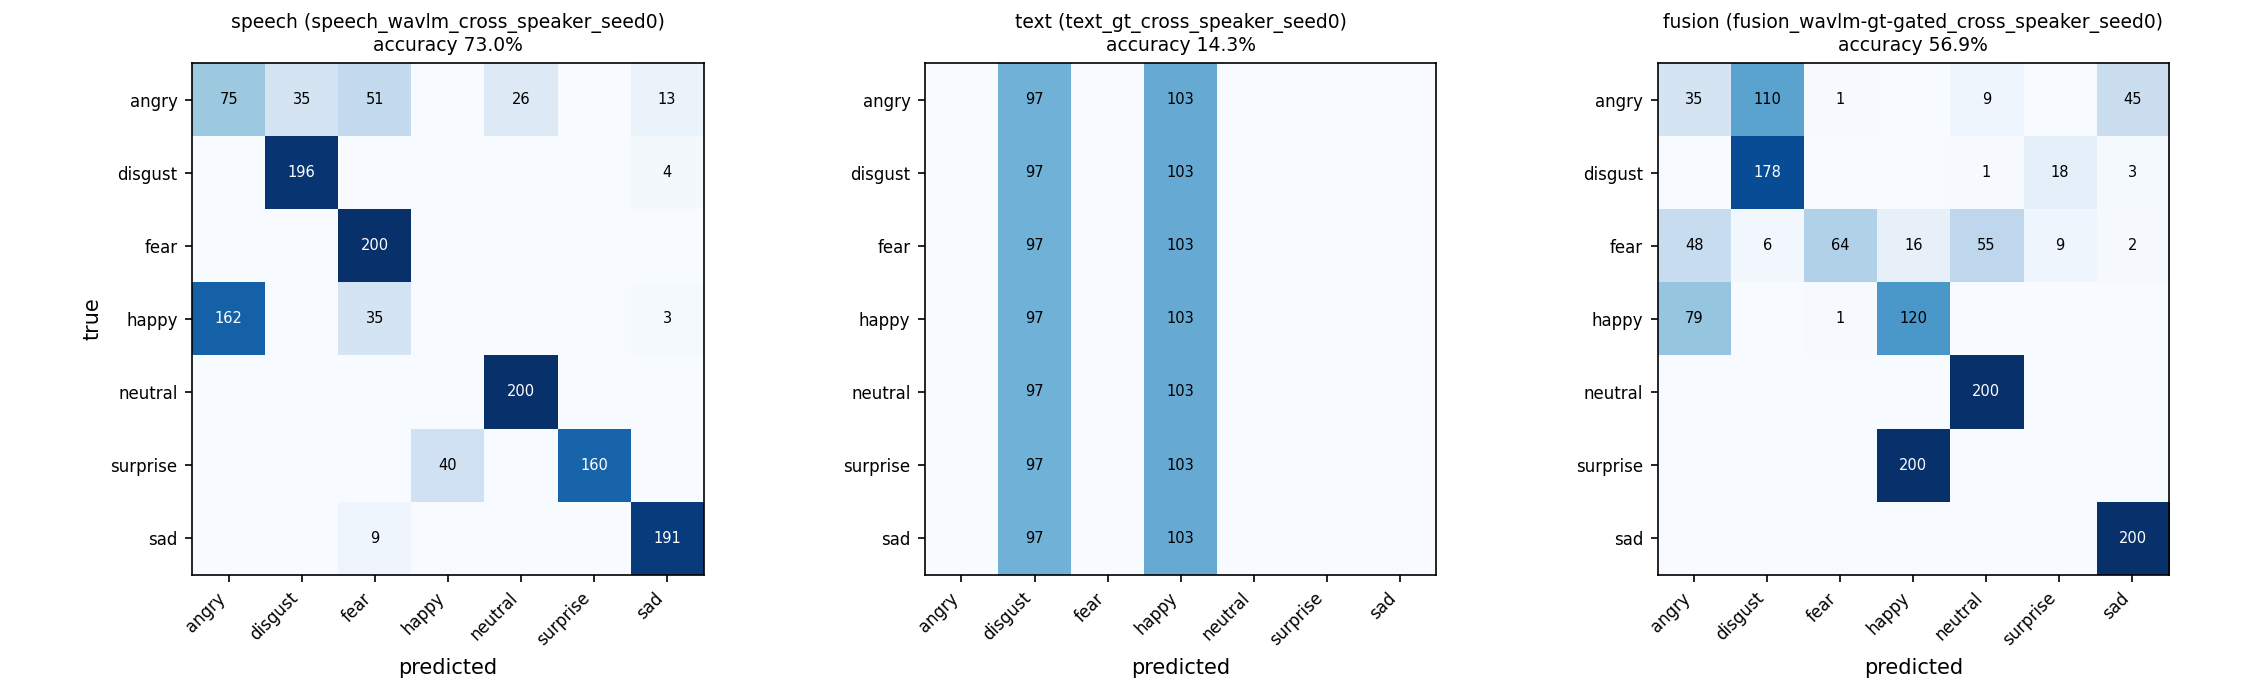

confusion_word.png


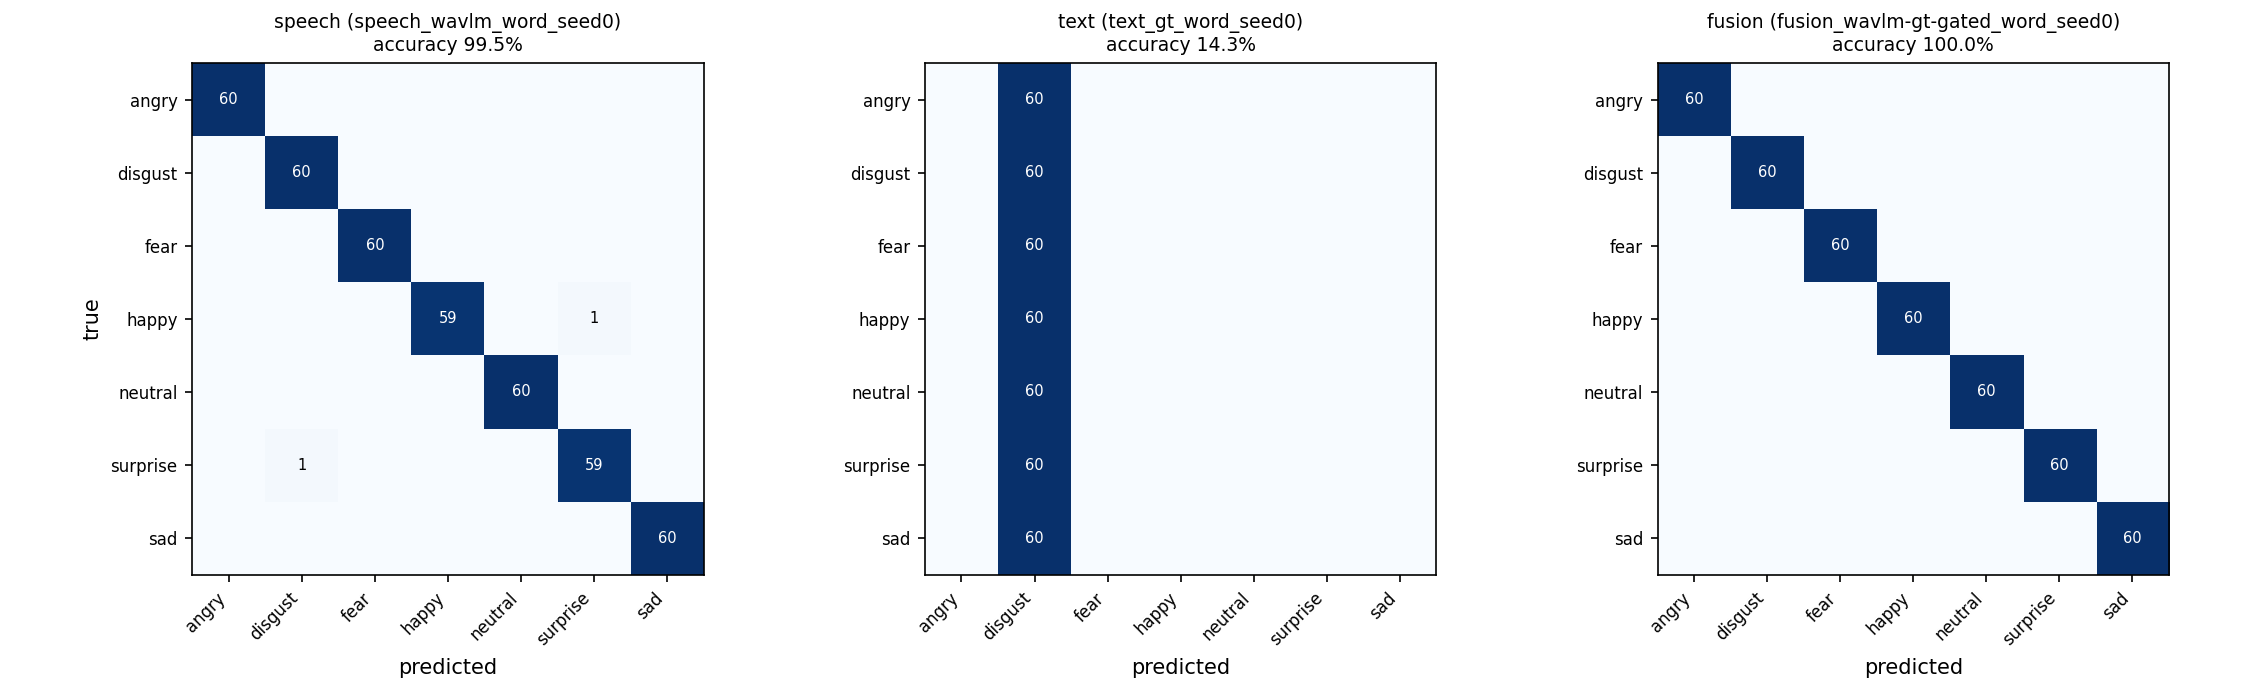

failure_cases.png


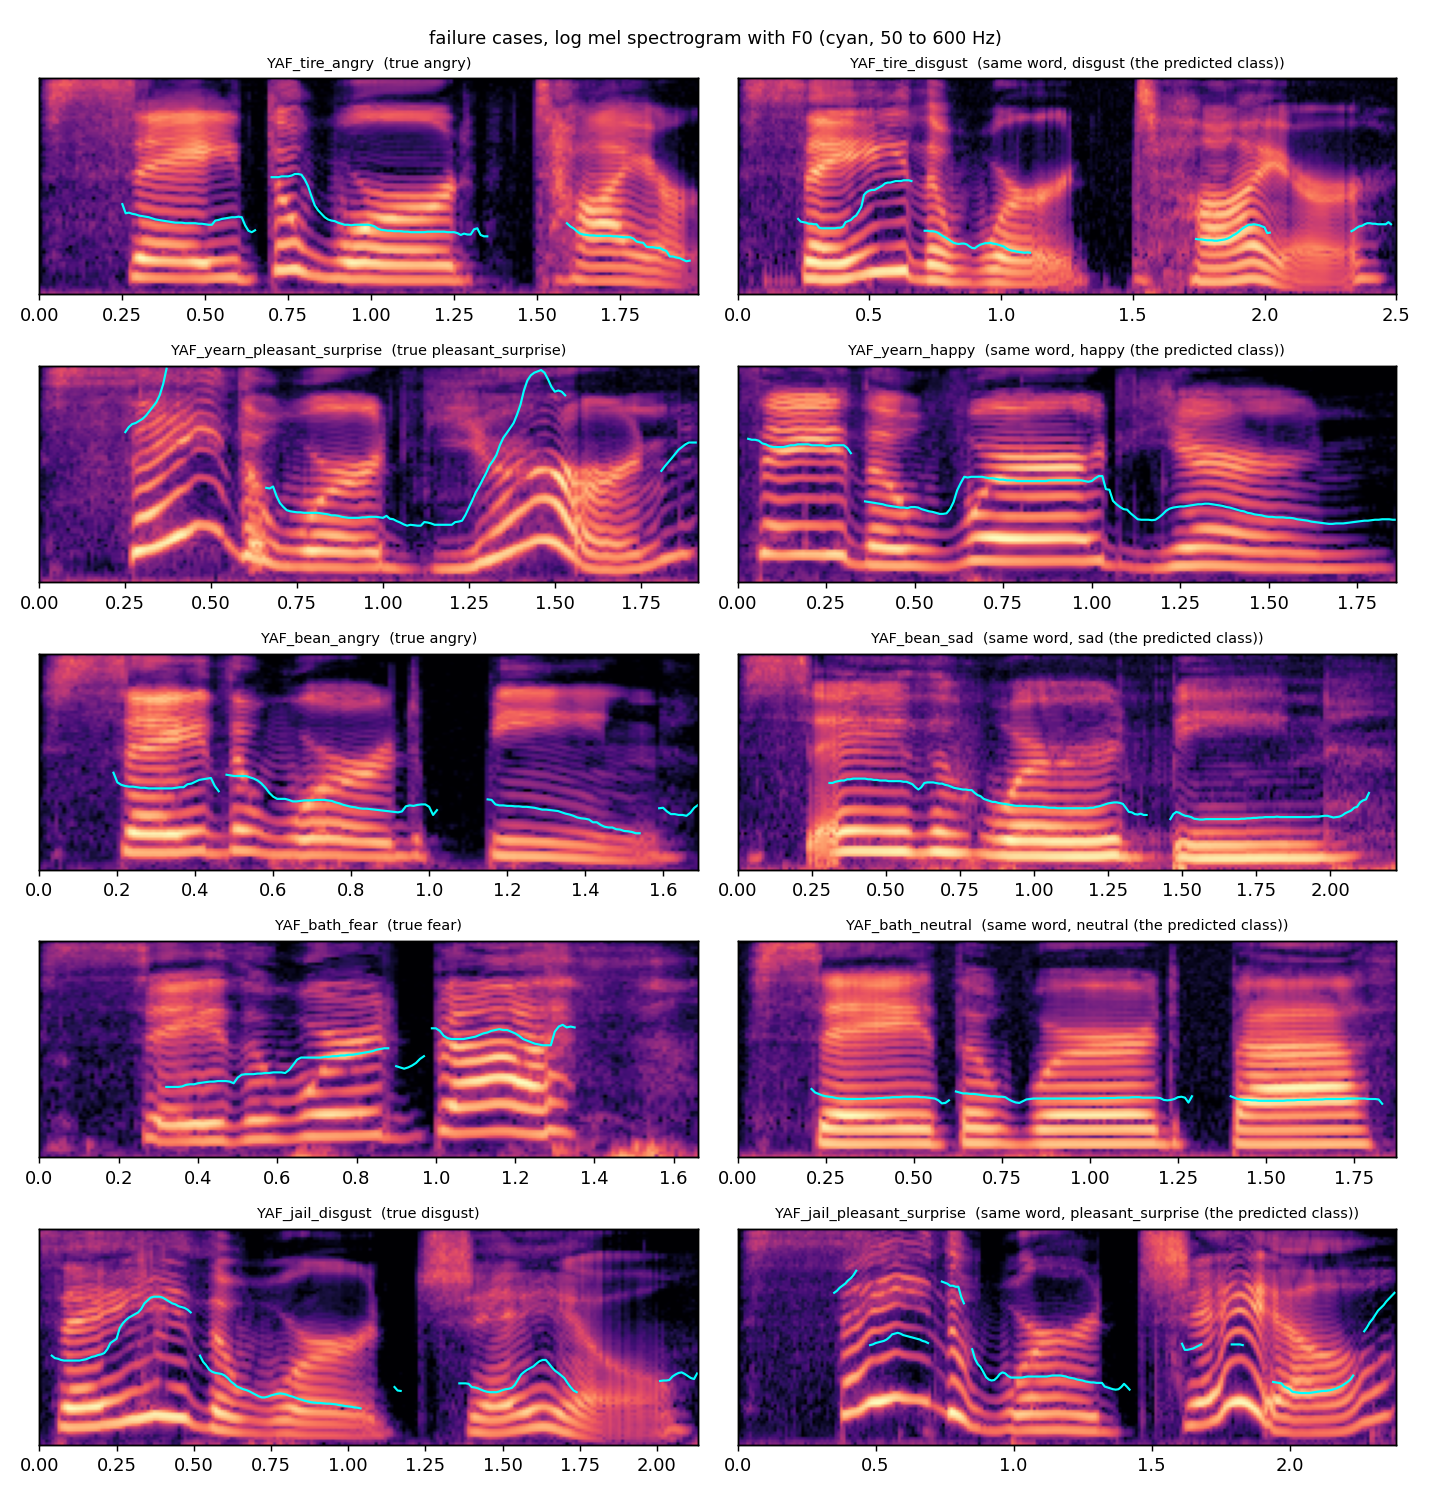

layer_weights.png


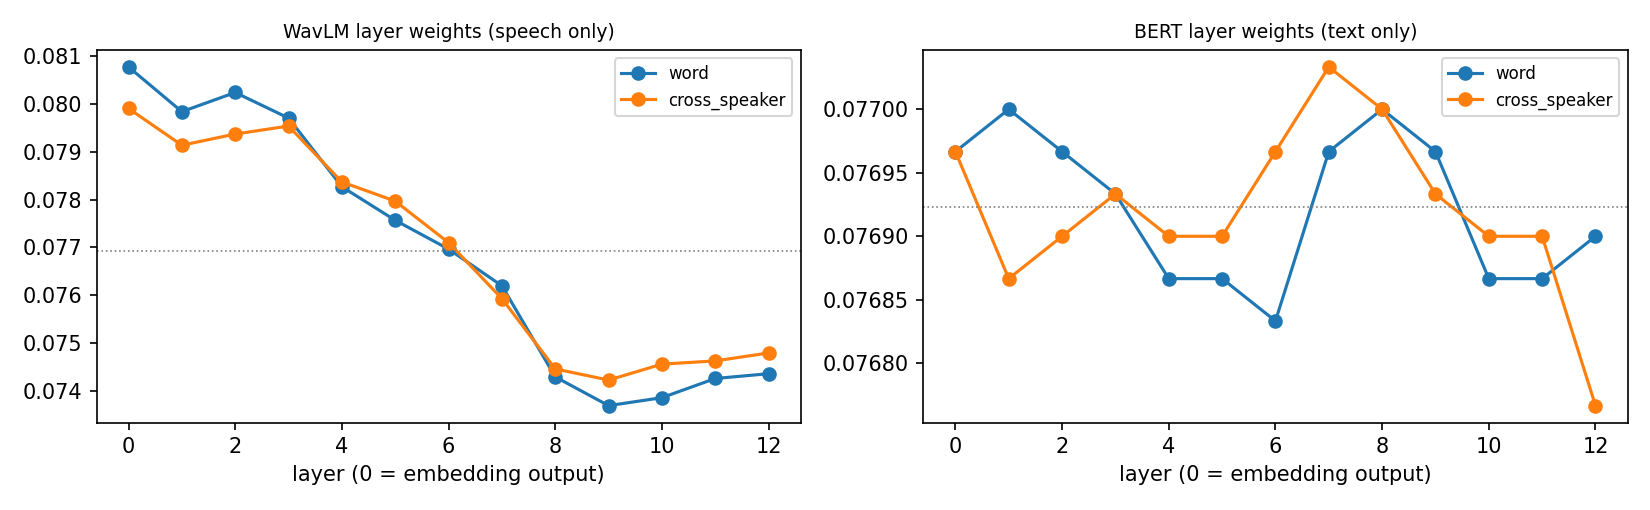

training_curves_cross_speaker.png


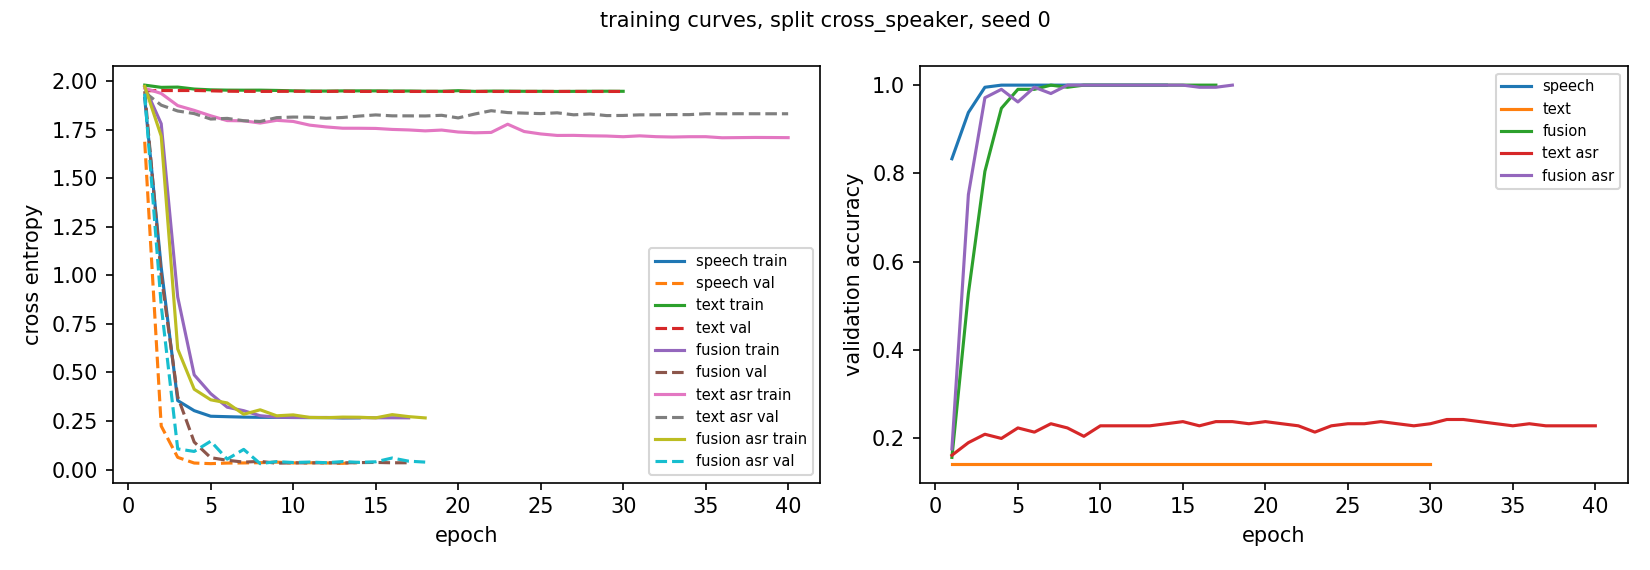

training_curves_word.png


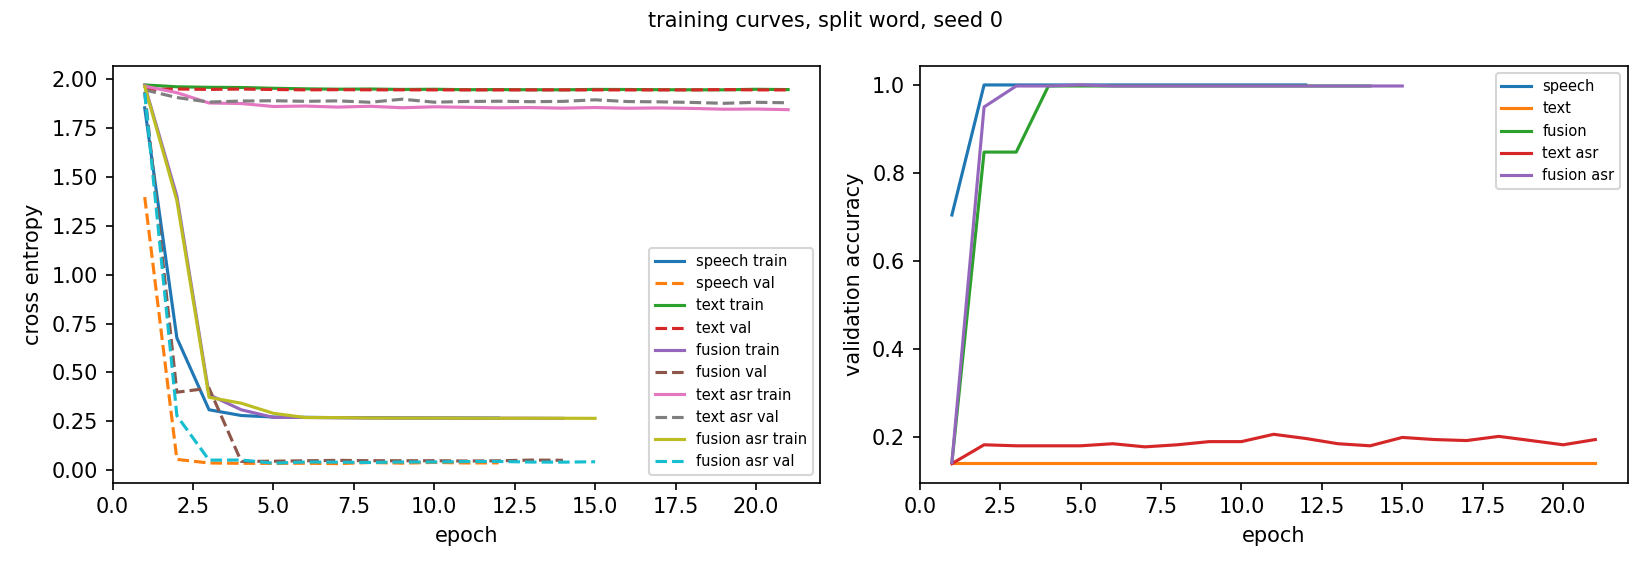

tsne_cross_speaker_asr.png


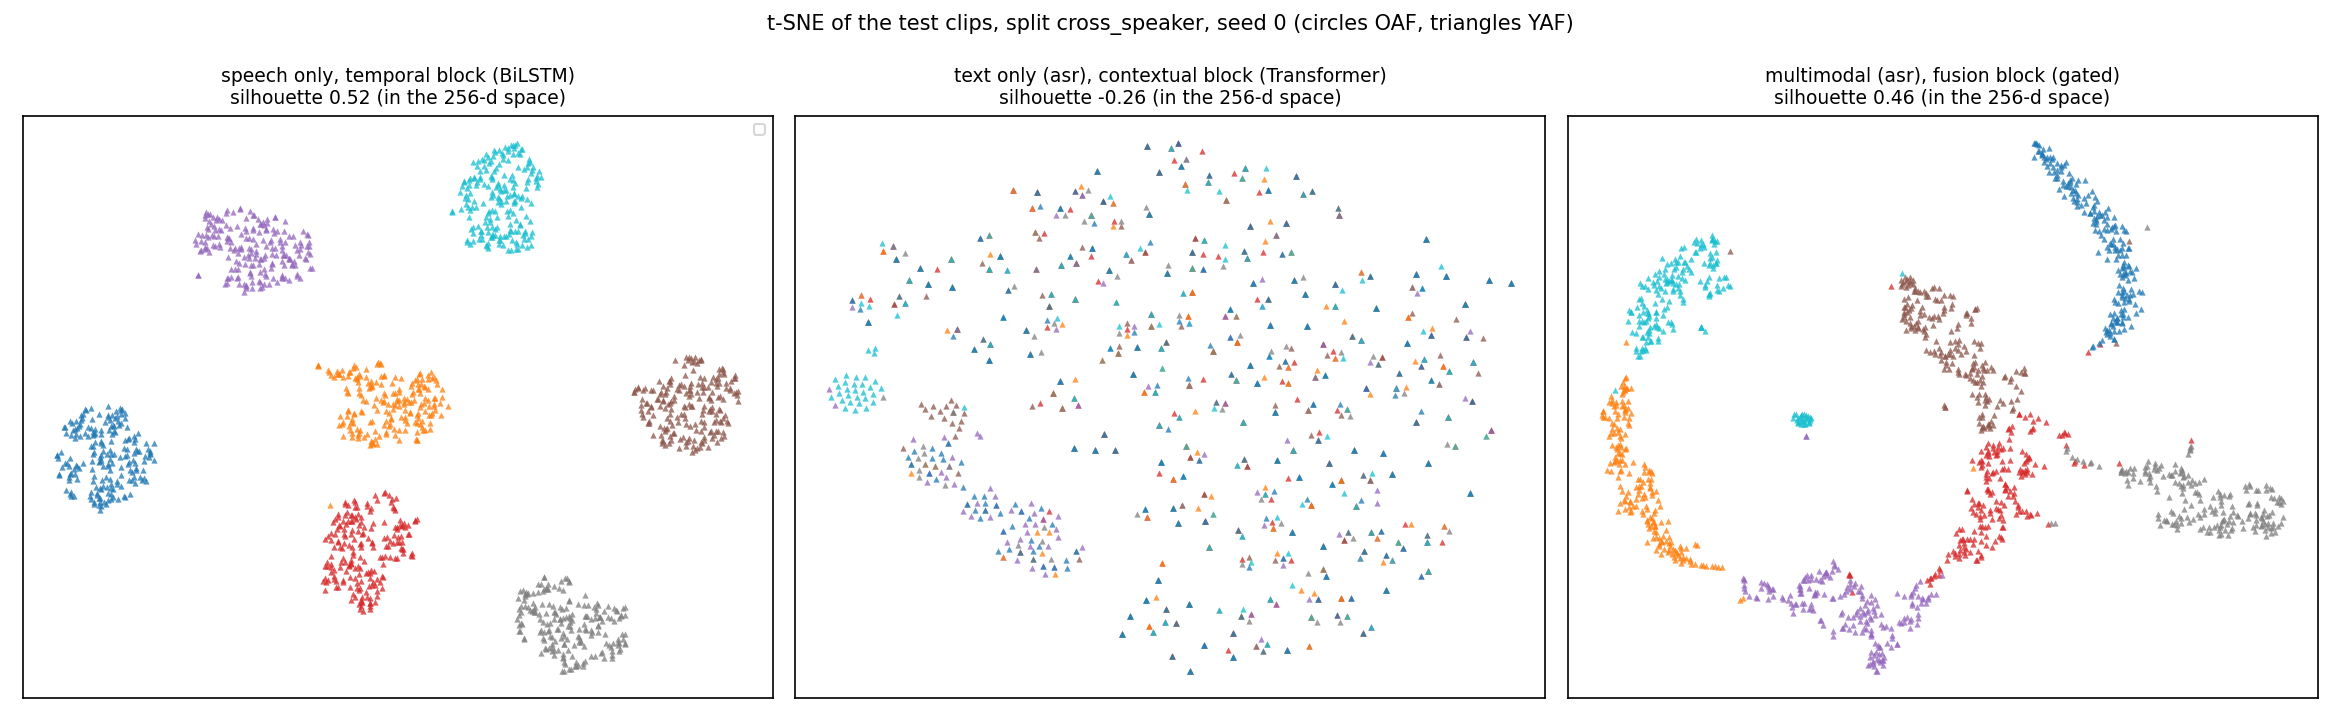

tsne_cross_speaker_gt.png


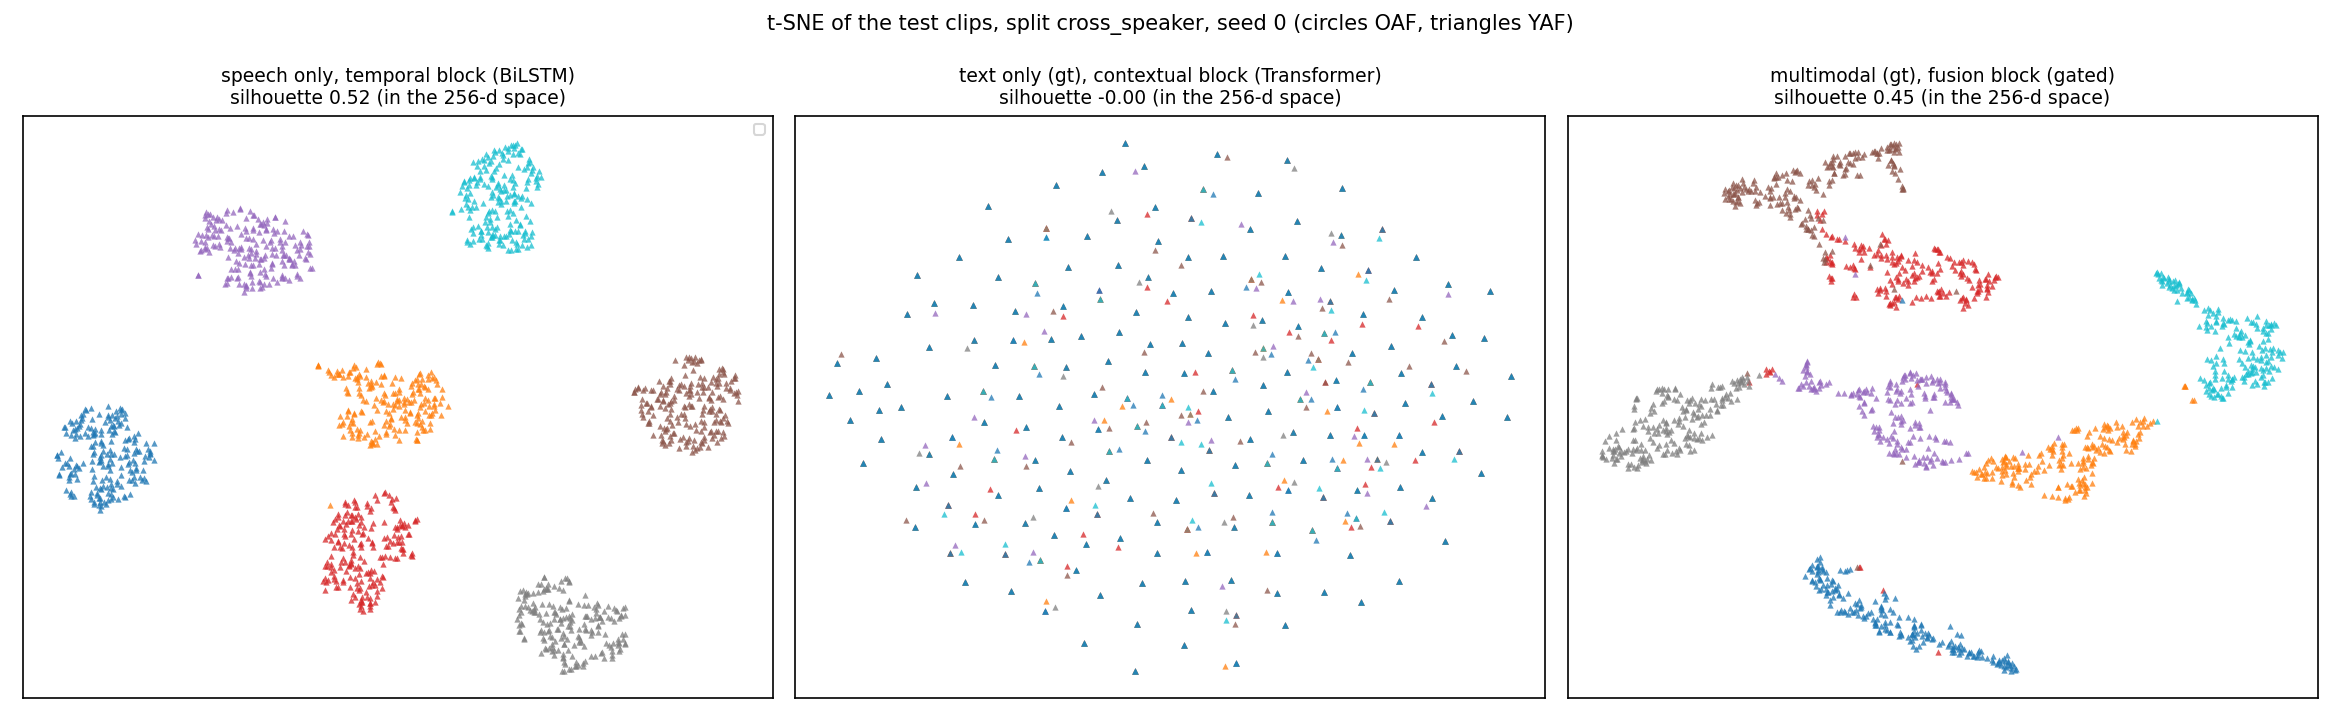

tsne_cross_speaker_inside_fusion.png


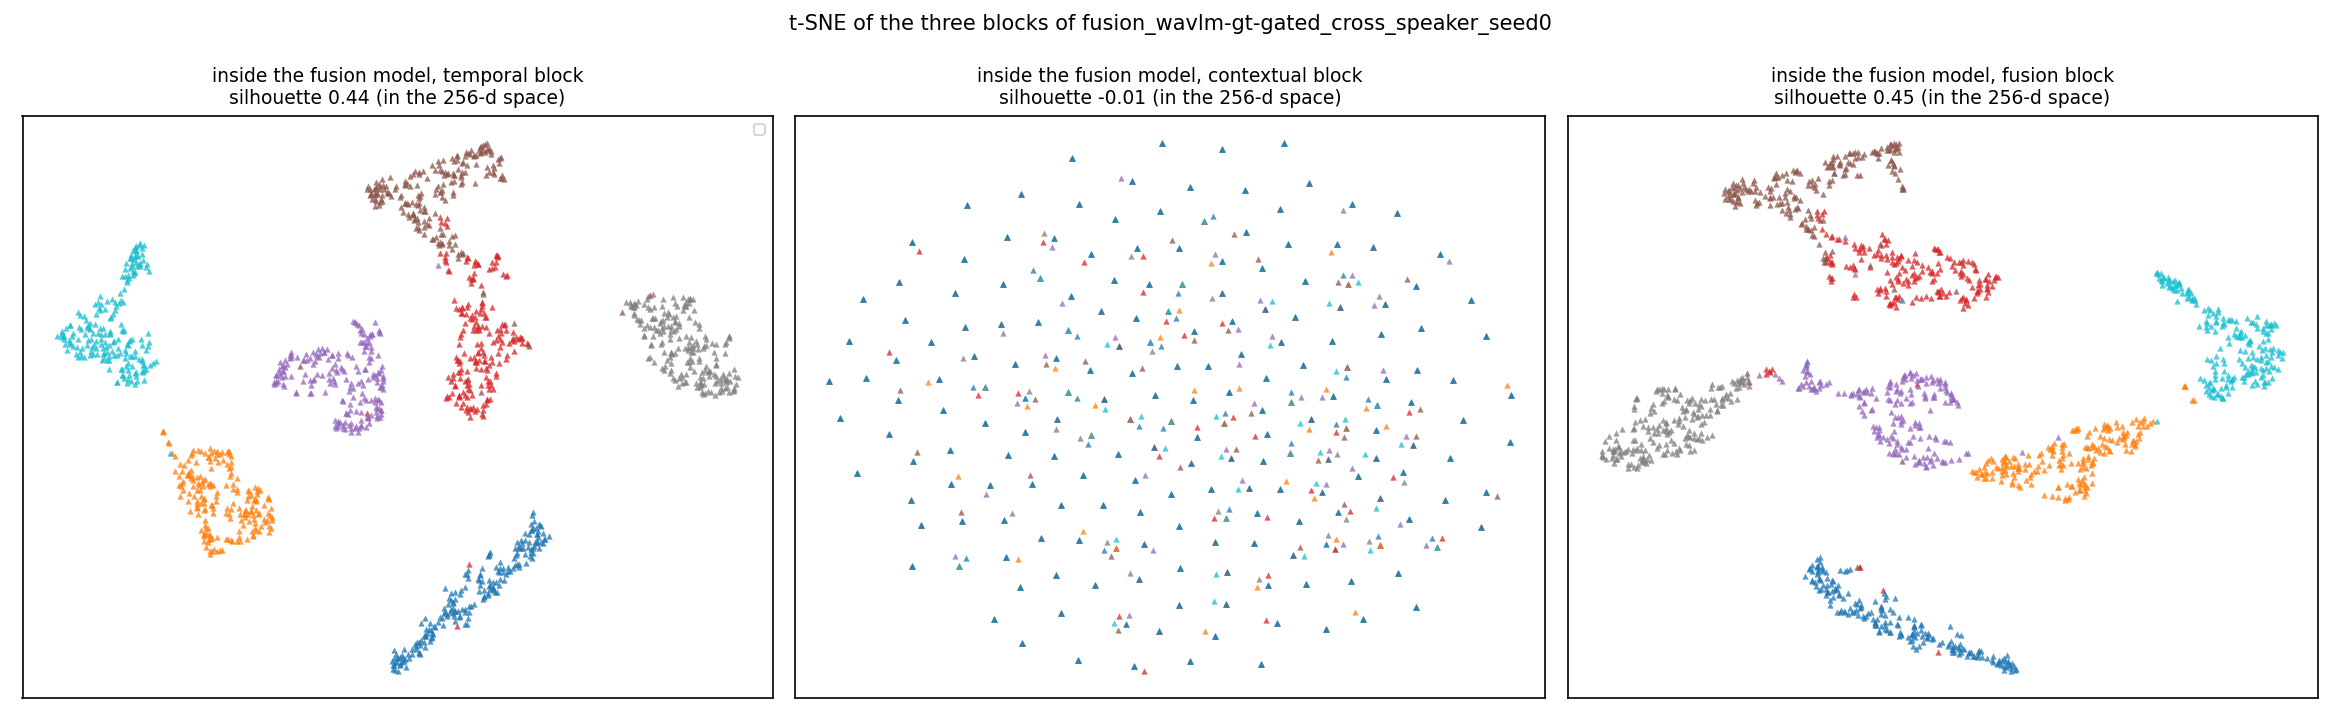

tsne_word_asr.png


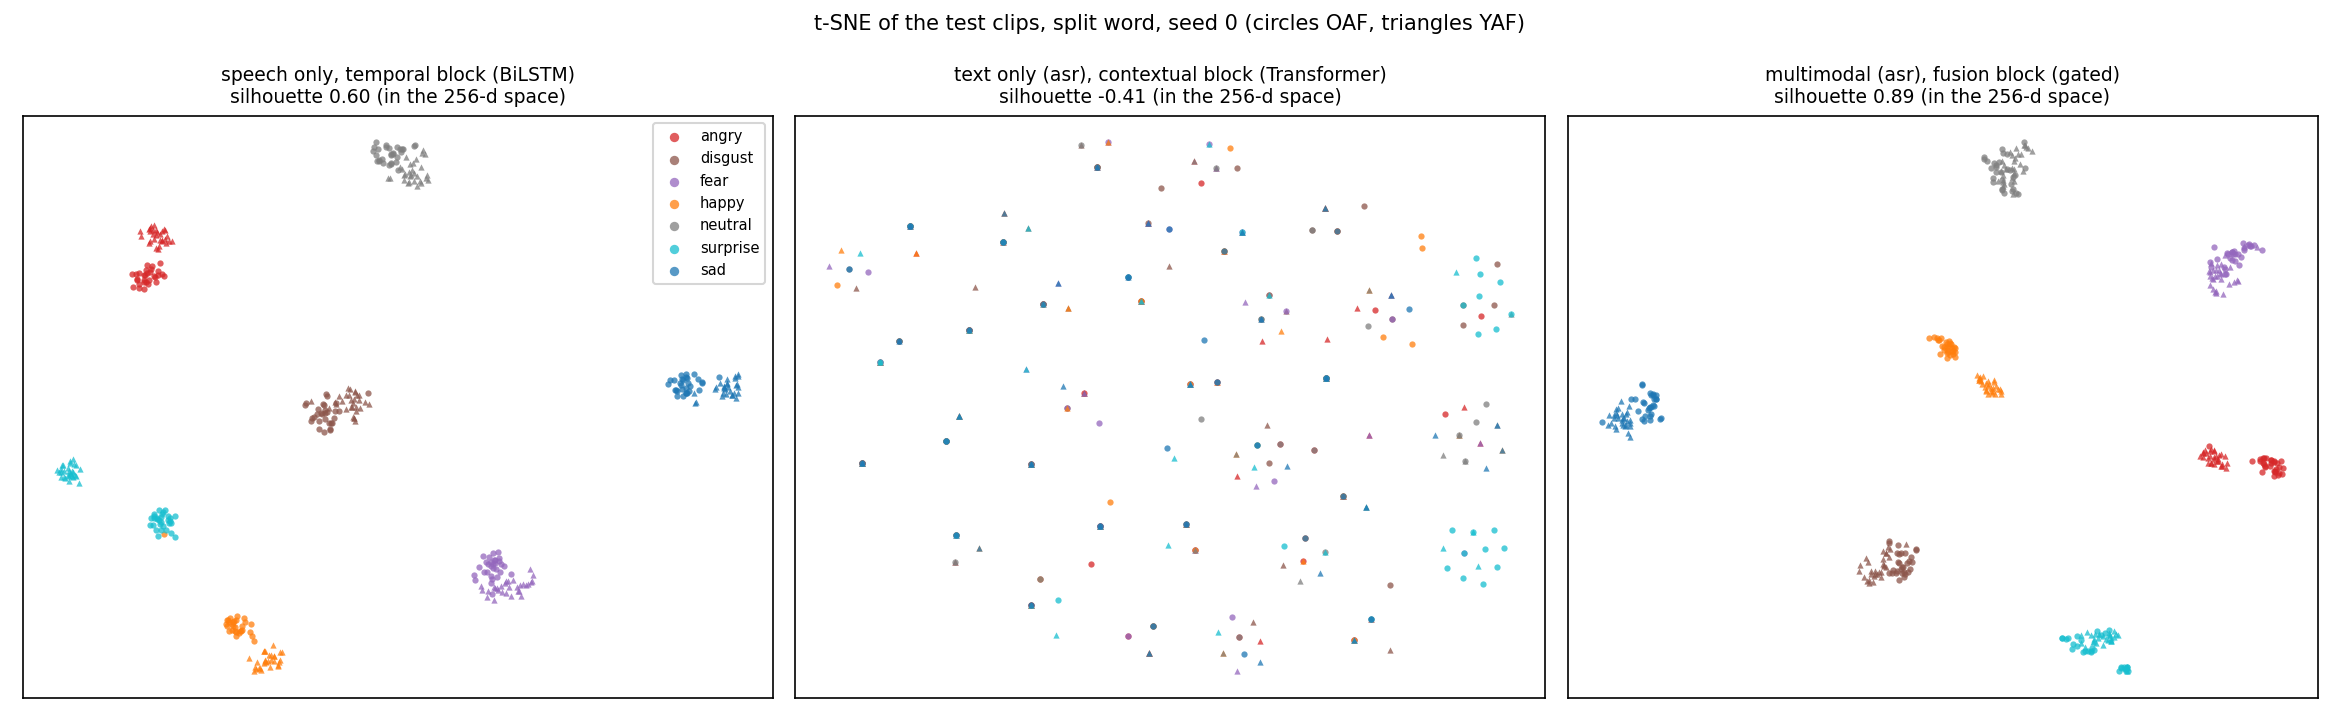

tsne_word_gt.png


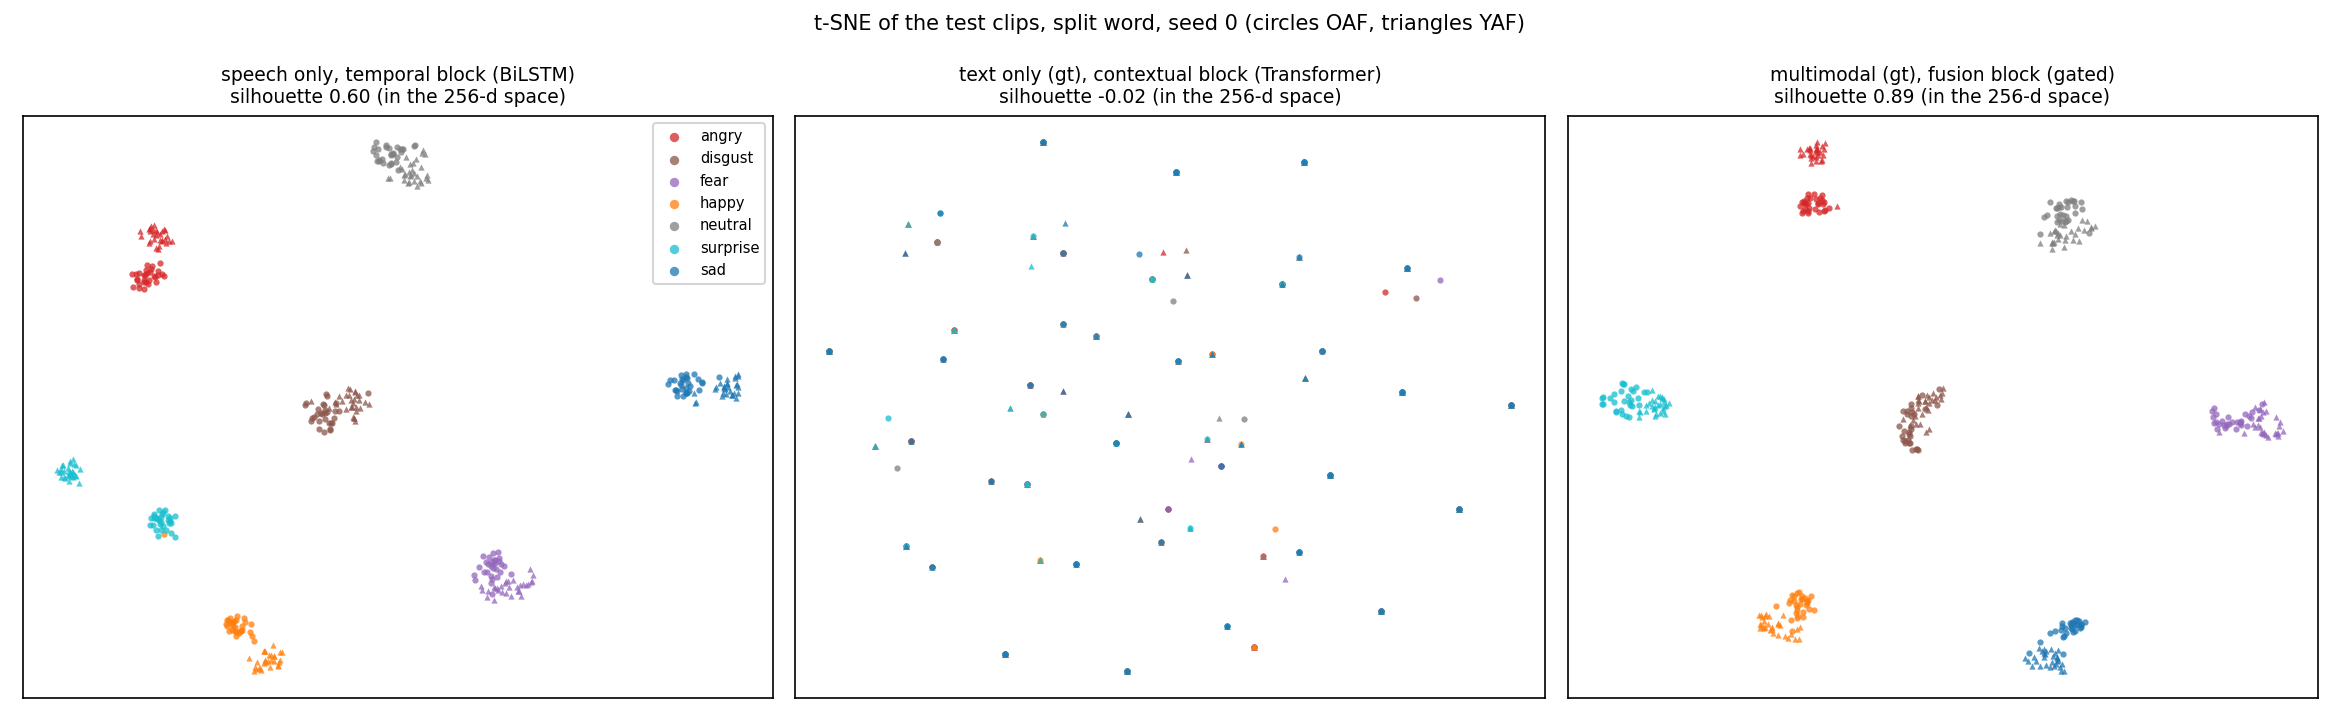

tsne_word_inside_fusion.png


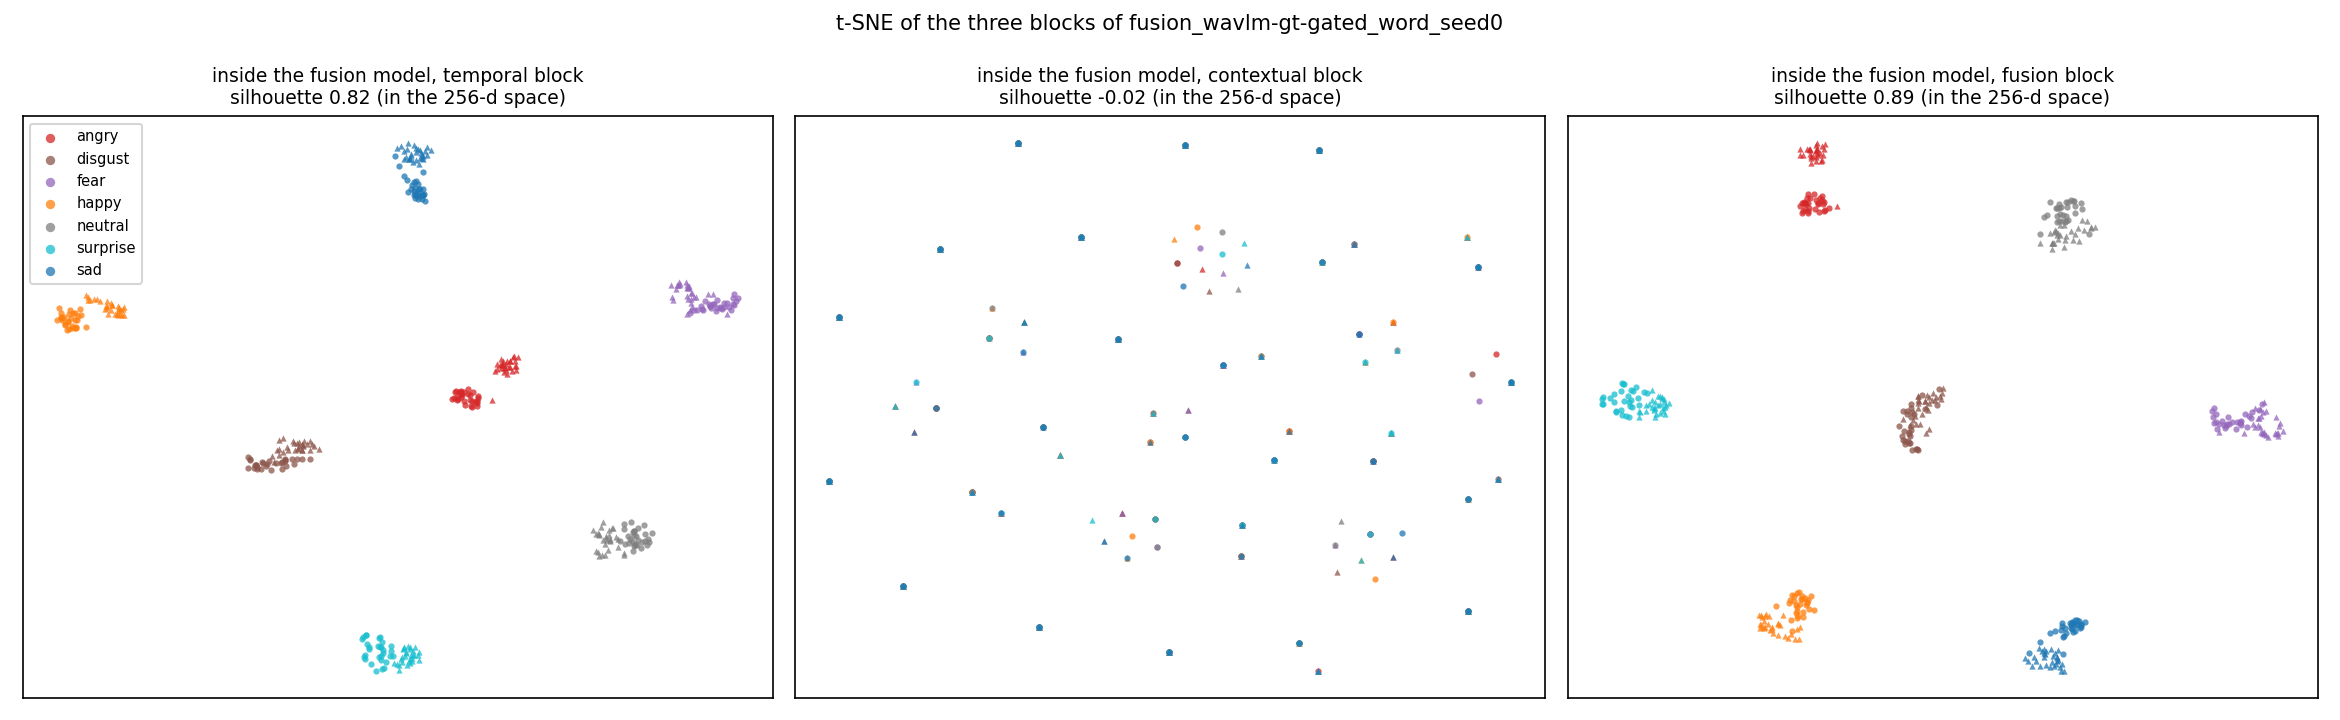

[2026-11-18 18:50:50 IST] uploaded results/A2b_results.zip (310.1 MB), copied to Drive
[2026-11-18 18:50:50 IST] finished in 79.1 s


In [10]:
run(f"{PY} -W ignore scripts/analyse.py", drop=r"(?i)warn")
from IPython.display import Image, Markdown, display
for f in ["accuracy_tables.md", "per_emotion.md", "fusion_vs_speech.md", "failure_cases.md"]:
    display(Markdown(open(f"Results/{f}").read()))
for f in sorted(os.listdir("Results/plots")):
    print(f)
    display(Image(f"Results/plots/{f}"))
upload_results()

## Save and disconnect

Saves the executed notebook, the logs, the cell timings and the results to Hugging Face and Google Drive, then
disconnects and deletes this runtime.

In [ ]:
finish("completed")

[2026-11-18 18:50:50 IST] notebook completed after 34.7 min, saving
